# Modelado Predictivo

Probaremos la Accuracy y el F1-Score entre 4 modelos para escoger el más apropiado: Regresión Logística, Árbol de Decisión, Random Forest, y CatBoost.

## Métricas

Con won (victoria del bando del peón) como clase positiva, y $TP$, $FP$, $FN$ los verdaderos positivos, falsos positivos y falsos negativos:

$$
\text{Precisión}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2\cdot \text{Precisión}\cdot\text{Recall}}{\text{Precisión}+\text{Recall}}
$$

El AUC-ROC es la probabilidad de que el modelo asigne mayor probabilidad de won a una posición won que a una nowin, tomadas al azar.

## Estrategia de validación

Comparar modelos con una sola partición entrenamiento/prueba puede llevar a elegir un modelo por azar. Por eso el procedimiento tiene dos etapas:

1. Se separa un 20 % de las posiciones como conjunto de prueba, de forma estratificada para conservar la proporción de clases (`random_state=42`).
2. La codificación One-Hot va dentro del Pipeline: aprende las categorías solo con las posiciones de entrenamiento y las aplica después a las de prueba, sin que la prueba influya en el entrenamiento.
3. Los cuatro candidatos se entrenan con el 80 % restante, con sus hiperparámetros por defecto, y se comparan en el conjunto de prueba mediante Accuracy y F1-Score de la clase `won`.
4. La decisión se confirma con validación cruzada estratificada repetida (5 particiones × 3 repeticiones = 15 evaluaciones por modelo) usando solo el 80 % de entrenamiento, junto con una línea base que siempre predice la clase mayoritaria y una prueba de Wilcoxon entre modelos.
5. El modelo seleccionado se reentrena, se evalúa en la prueba con la matriz de confusión, la curva ROC y un intervalo de confianza para la exactitud, se interpreta mediante la importancia por permutación, y se comprueba su estabilidad con otras particiones. Su pipeline completo se guarda para el dashboard.

In [24]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from scipy.stats import wilcoxon, chi2_contingency

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV, validation_curve, learning_curve)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             make_scorer, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from catboost import CatBoostClassifier
import joblib, json, sklearn

warnings.filterwarnings("ignore")

SEED = 42
POS = "won"                       # clase positiva
COLOR_WON, COLOR_NOWIN = "#008080", "#40B5A0"
TEAL = LinearSegmentedColormap.from_list("teal", ["#F0FFFF", "#008080"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
f1_scorer = make_scorer(f1_score, pos_label=POS)

## Comparación preliminar de los modelos

In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

%store -r datos
df = datos.copy()

# 1. Separar X (predictoras) e y (target)
X = df.drop(columns=['class'])
y = df['class']

# 2. Transformador que codifica las variables categóricas (One-Hot)
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), X.columns)
    ])

# 3. Dividir en 80 % entrenamiento y 20 % prueba (estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from catboost import CatBoostClassifier

# Definimos 3 modelos candidatos
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=2000),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0)
}

resultados = []

for nombre, algoritmo in modelos.items():
    pipe = Pipeline(steps=[
        ('preprocesador', preprocesador),
        ('modelo', algoritmo)
    ])
    
    # Entrenamos
    pipe.fit(X_train, y_train)
    
    # Predecimos
    y_pred = pipe.predict(X_test)
    
    # Calculamos métricas
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label='won')
    
    resultados.append({"Modelo": nombre, "Accuracy": acc, "F1-Score": f1})

# Mostrar la tabla comparativa
df_resultados = pd.DataFrame(resultados).sort_values(by="F1-Score", ascending=False)
display(df_resultados)

,Modelo,Accuracy,F1-Score
3,CatBoost,0.995313,0.995502
1,Árbol de Decisión,0.993750,0.993976
2,Random Forest,0.990625,0.990991
0,Regresión Logística,0.960938,0.962406


En la partición de prueba, CatBoost obtiene el mejor resultado (Accuracy = 0.9953, F1-Score = 0.9955), seguido del Árbol de Decisión (0.9938; 0.9940), Random Forest (0.9906; 0.9910) y la Regresión Logística (0.9609; 0.9624). La diferencia entre CatBoost y el árbol equivale a una sola posición de las 640 de prueba, por lo que no es concluyente. La brecha con la regresión logística (≈ 3.4 puntos de exactitud) sí es amplia. Todos los modelos superan con holgura la referencia del 52 % de la clase mayoritaria.

## Validación cruzada

Para que la elección no dependa de una sola partición, cada modelo se evalúa 15 veces (validación cruzada estratificada de 5 particiones, repetida 3 veces) usando únicamente el 80 % de entrenamiento. Se añade una línea base que siempre predice la clase mayoritaria. 

In [37]:
# Validación cruzada estratificada repetida (solo con el 80 % de entrenamiento) ──
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)      # 15 evaluaciones por modelo
scoring = {"accuracy": "accuracy", "f1": f1_scorer, "roc_auc": "roc_auc"}

# Los 4 modelos de arriba + una línea base que siempre predice la clase mayoritaria
candidatos = {"Baseline: clase mayoritaria": DummyClassifier(strategy="most_frequent")}
candidatos.update(modelos)

cv_res = {}
for nombre, algoritmo in candidatos.items():
    pipe_cv = Pipeline([("preprocesador", clone(preprocesador)), ("modelo", clone(algoritmo))])
    cv_res[nombre] = cross_validate(pipe_cv, X_train, y_train, cv=cv, scoring=scoring,
                                    return_train_score=True, n_jobs=1 if "CatBoost" in nombre else -1)

In [38]:
filas = []
for nombre, r in cv_res.items():
    filas.append({"Modelo": nombre,
                  "Accuracy": f"{r['test_accuracy'].mean():.4f} ± {r['test_accuracy'].std():.4f}",
                  "F1 (won)": f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
                  "AUC-ROC":  f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}",
                  "Brecha train − val (acc)": round((r["train_accuracy"] - r["test_accuracy"]).mean(), 4),
                  "_f1": r["test_f1"].mean()})
tabla_cv = (pd.DataFrame(filas).sort_values("_f1", ascending=False)
              .drop(columns="_f1").set_index("Modelo"))
tabla_cv

,Accuracy,F1 (won),AUC-ROC,Brecha train − val (acc)
Modelo,,,,
CatBoost,0.9913 ± 0.0032,0.9916 ± 0.0030,0.9995 ± 0.0007,0.0069
Árbol de Decisión,0.9907 ± 0.0051,0.9911 ± 0.0049,0.9922 ± 0.0046,0.0085
Random Forest,0.9883 ± 0.0055,0.9888 ± 0.0053,0.9987 ± 0.0016,0.0110
Regresión Logística,0.9615 ± 0.0085,0.9631 ± 0.0081,0.9930 ± 0.0026,0.0044
Baseline: clase mayoritaria,0.5223 ± 0.0004,0.6862 ± 0.0004,0.5000 ± 0.0000,-0.0000


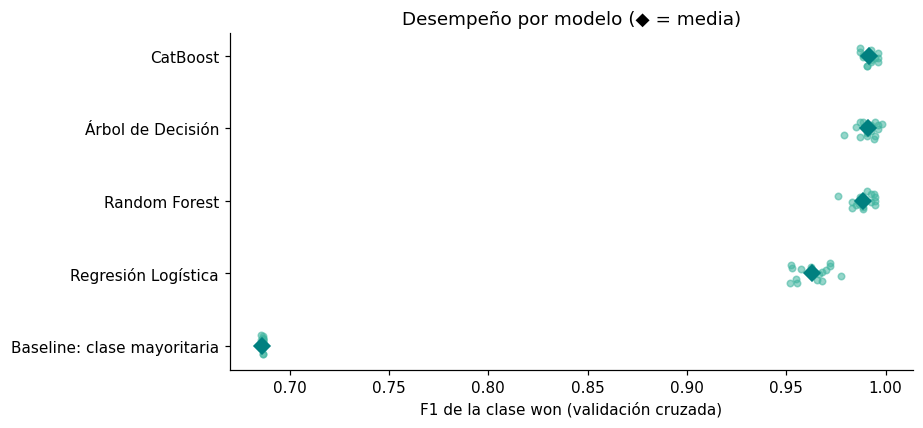

In [29]:
# Distribución de los 15 valores de F1 de cada modelo (un punto = una partición)
rng = np.random.default_rng(SEED)
orden = list(tabla_cv.index[::-1])

fig, ax = plt.subplots(figsize=(8.5, 4))
for i, n in enumerate(orden):
    v = cv_res[n]["test_f1"]
    ax.scatter(v, i + rng.uniform(-.15, .15, len(v)), s=18, alpha=.55, color=COLOR_NOWIN)
    ax.plot(v.mean(), i, marker="D", color=COLOR_WON, markersize=7)
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden)
ax.set_xlabel("F1 de la clase won (validación cruzada)")
ax.set_title("Desempeño por modelo (◆ = media)")
plt.tight_layout(); plt.show()

En validación cruzada, CatBoost vuelve a obtener el mayor F1 medio (0.9916 ± 0.0030), seguido del Árbol de Decisión (0.9911 ± 0.0049), Random Forest (0.9888 ± 0.0053) y la Regresión Logística (0.9631 ± 0.0081). La línea base de la clase mayoritaria queda en una exactitud de 0.522 y un AUC de 0.5, de modo que los cuatro modelos capturan señal real. Las brechas entre entrenamiento y validación son pequeñas en todos (entre 0.004 y 0.011), así que no hay sobreajuste preocupante. En el gráfico, los tres modelos basados en árboles se solapan casi por completo y la regresión logística queda claramente por debajo. CatBoost tiene además el AUC-ROC más alto y estable (0.9995 ± 0.0007, frente a 0.9922 ± 0.0046 del árbol).

### Las diferencias entre modelos son reales o son ruido?

Como todos los modelos se evalúan sobre las mismas 15 particiones, se puede comparar el F1 de CatBoost con el de cada uno de los demás, partición por partición (prueba de rangos con signo de Wilcoxon). Cuando dos modelos empatan en todas las particiones, el p-valor se reporta como 1.

In [30]:
# ¿Las diferencias son reales o ruido? Se comparan los modelos partición por partición (Wilcoxon)
MODELO = "CatBoost"
f1_folds = {n: r["test_f1"] for n, r in cv_res.items()}
reales = [n for n in cv_res if not n.startswith("Baseline")]
mejor_cv = max(reales, key=lambda n: f1_folds[n].mean())

comp = []
for n in reales:
    if n == MODELO:
        continue
    d = f1_folds[MODELO] - f1_folds[n]
    try:
        p = float(wilcoxon(d).pvalue)
    except ValueError:                      # todas las diferencias son exactamente cero
        p = 1.0
    if np.isnan(p):
        p = 1.0
    comp.append({"Modelo": n, "dif": d.mean(), "gana": (d >= 0).mean() * 100, "p": p})

tabla_comp = pd.DataFrame(comp).set_index("Modelo")
tabla_comp.columns = ["Dif. media de F1 (CatBoost − modelo)", "% de particiones donde CatBoost gana o empata", "p (Wilcoxon)"]
display(tabla_comp.round(4))

sup = [c["Modelo"] for c in comp if c["p"] < 0.05 and c["dif"] > 0]
inf = [c["Modelo"] for c in comp if c["p"] < 0.05 and c["dif"] < 0]
emp = [c["Modelo"] for c in comp if c["p"] >= 0.05]
partes = []
if sup: partes.append("supera de forma estadísticamente significativa a " + ", ".join(sup))
if emp: partes.append("no se distingue estadísticamente de " + ", ".join(emp))
if inf: partes.append("es significativamente **peor** que " + ", ".join(inf))
frase_cb = "CatBoost " + "; ".join(partes) + "."

base_acc = cv_res["Baseline: clase mayoritaria"]["test_accuracy"].mean()
aviso = "" if mejor_cv == MODELO else f" Ojo: el mejor F1 medio de esta comparación es el de {mejor_cv}, no el de CatBoost."
display(Markdown(
    f"En validación cruzada (15 evaluaciones por modelo), CatBoost obtiene un F1 medio de {f1_folds[MODELO].mean():.4f}; "
    f"{frase_cb} La línea base de la clase mayoritaria alcanza una exactitud de {base_acc:.3f}." + aviso))

,Dif. media de F1 (CatBoost − modelo),% de particiones donde CatBoost gana o empata,p (Wilcoxon)
Modelo,,,
Regresión Logística,0.0285,100.0000,0.0001
Árbol de Decisión,0.0005,46.6667,0.8469
Random Forest,0.0029,80.0000,0.0479


En validación cruzada (15 evaluaciones por modelo), CatBoost obtiene un F1 medio de 0.9916; CatBoost supera de forma estadísticamente significativa a Regresión Logística, Random Forest; no se distingue estadísticamente de Árbol de Decisión. La línea base de la clase mayoritaria alcanza una exactitud de 0.522.

CatBoost supera de forma significativa a la Regresión Logística (diferencia media de F1 de 0.0285; gana en el 100 % de las particiones; p = 0.0001) y, con un margen mínimo, a Random Forest (0.0029; p = 0.048). No se distingue del Árbol de Decisión (0.0005; p = 0.85). Como las particiones comparten datos, los p-valores son algo optimistas, y la ventaja sobre Random Forest debe tomarse como marginal. Lo que sí indican los resultados es que la señal no es puramente aditiva: la regresión logística, que suma efectos independientes, queda unos 3 puntos de F1 por debajo de los modelos de árboles, que pueden representar combinaciones de condiciones tácticas. Entre los modelos de árboles las diferencias son demasiado pequeñas para declarar un ganador claro. Se selecciona CatBoost por tener el F1 medio más alto con la menor variabilidad entre particiones y el mejor AUC, algo útil porque el dashboard mostrará probabilidades.

## Modelo final

Con CatBoost seleccionado, se entrena el pipeline completo (One-Hot + CatBoost) sobre el conjunto de entrenamiento y se guarda en `modelo_ajedrez.pkl`. 

In [31]:
import joblib

mejor_modelo = CatBoostClassifier(random_state=42, verbose=0, allow_writing_files=False)

pipeline_ganador = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', mejor_modelo)
])

pipeline_ganador.fit(X_train, y_train)

joblib.dump(pipeline_ganador, "modelo_ajedrez.pkl");

,Accuracy,Precisión,Recall,F1,AUC-ROC
CatBoost (prueba),0.9953,0.997,0.994,0.9955,0.9996


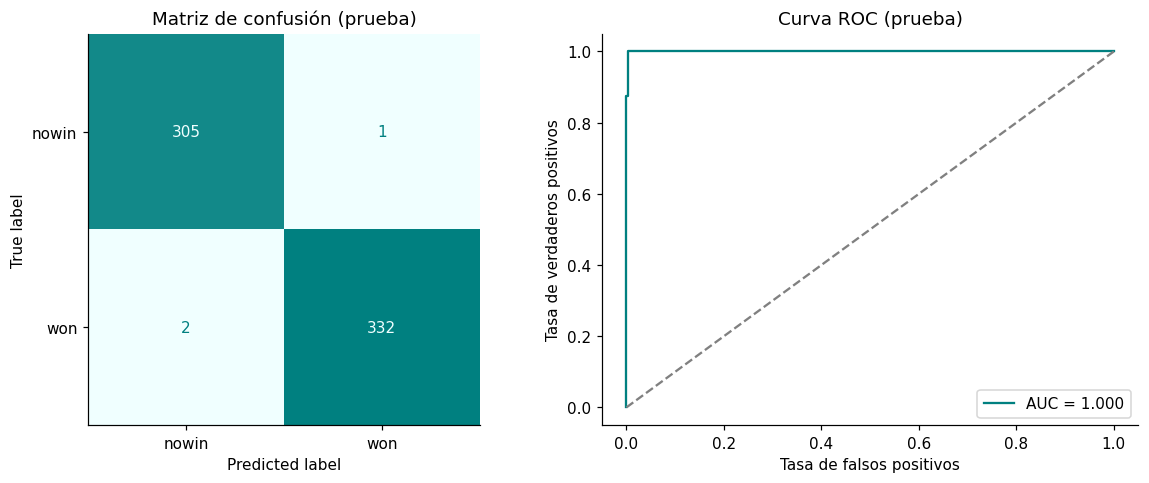

              precision    recall  f1-score   support

       nowin     0.9935    0.9967    0.9951       306
         won     0.9970    0.9940    0.9955       334

    accuracy                         0.9953       640
   macro avg     0.9952    0.9954    0.9953       640
weighted avg     0.9953    0.9953    0.9953       640



En 640 posiciones de prueba el modelo acierta 637 y falla 3: exactitud = 0.9953, con intervalo bootstrap al 95 % de [0.9891, 1.0000]. De los errores, 1 son falsos *won* y 2 son falsos *nowin*.

In [32]:
from sklearn.metrics import roc_curve
y_pred = np.asarray(pipeline_ganador.predict(X_test)).ravel()
y_proba = pipeline_ganador.predict_proba(X_test)[:, list(pipeline_ganador.classes_).index(POS)]
mask_err = (y_pred != y_test.to_numpy())

metricas_test = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precisión": precision_score(y_test, y_pred, pos_label=POS),
    "Recall":    recall_score(y_test, y_pred, pos_label=POS),
    "F1":        f1_score(y_test, y_pred, pos_label=POS),
    "AUC-ROC":   roc_auc_score(y_test == POS, y_proba),
}
display(pd.DataFrame(metricas_test, index=["CatBoost (prueba)"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["nowin", "won"], cmap=TEAL,
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión (prueba)")
fpr, tpr, _ = roc_curve(y_test == POS, y_proba)
axes[1].plot(fpr, tpr, color=COLOR_WON, label=f"AUC = {metricas_test['AUC-ROC']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC (prueba)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, digits=4))

# Incertidumbre de la exactitud: intervalo bootstrap (2000 remuestreos del conjunto de prueba)
acierto = (~mask_err).astype(int)
rng = np.random.default_rng(SEED)
boots = np.array([rng.choice(acierto, size=len(acierto), replace=True).mean() for _ in range(2000)])
ic_acc = np.percentile(boots, [2.5, 97.5])

display(Markdown(
    f"En {len(y_test)} posiciones de prueba el modelo acierta {int(acierto.sum())} y falla {len(acierto) - int(acierto.sum())}: "
    f"exactitud = {acierto.mean():.4f}, con intervalo bootstrap al 95 % de [{ic_acc[0]:.4f}, {ic_acc[1]:.4f}]. "
    f"De los errores, {int(((y_pred == 'won') & mask_err).sum())} son falsos *won* y "
    f"{int(((y_pred == 'nowin') & mask_err).sum())} son falsos *nowin*."))

En las 640 posiciones de prueba, el modelo acierta 637 y falla 3 (exactitud = 0.9953). Hay un falso won (una posición nowin que el modelo predice como victoria del peón) y dos falsos nowin. La precisión de won es 0.9970, el recall 0.9940 y el AUC-ROC es prácticamente 1. Con un conjunto de prueba tan pequeño, una posición de diferencia mueve la exactitud en 0.0016. Por eso el resultado debe leerse junto con el intervalo bootstrap al 95 % que muestra la celda.

### Interpretabilidad: qué variables usa el modelo?

La importancia por permutación mide cuánto cae el F1 en el conjunto de prueba al barajar al azar los valores de una variable: si el modelo depende de ella, el desempeño empeora. Se calcula sobre el pipeline completo, de modo que cada variable se permuta con sus categorías originales.

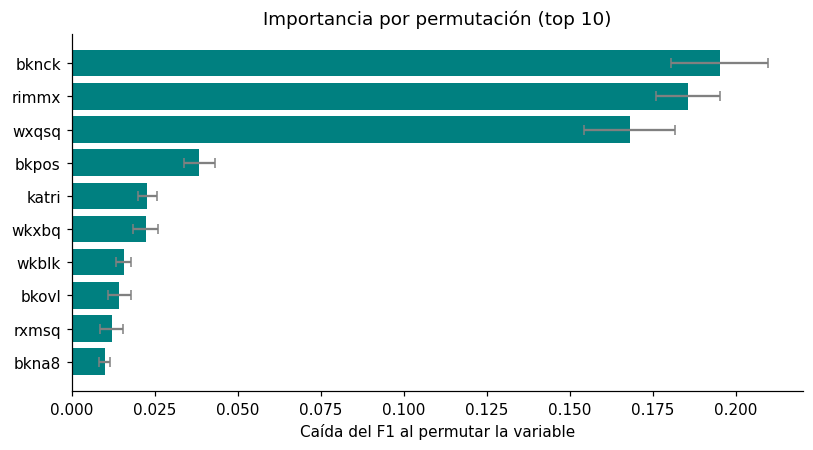

In [33]:
def f1_won(est, Xd, yd):
    return f1_score(yd, np.asarray(est.predict(Xd)).ravel(), pos_label=POS)

perm = permutation_importance(pipeline_ganador, X_test, y_test, scoring=f1_won,
                              n_repeats=20, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"variable": list(X_test.columns),
                     "caída del F1": perm.importances_mean, "sd": perm.importances_std})
         .sort_values("caída del F1", ascending=False).reset_index(drop=True))

top10 = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top10["variable"], top10["caída del F1"], xerr=top10["sd"], color=COLOR_WON, ecolor="grey", capsize=3)
ax.set_xlabel("Caída del F1 al permutar la variable"); ax.set_title("Importancia por permutación (top 10)")
plt.tight_layout(); plt.show()

Coincide con lo que mostró el EDA? Se compara con la V de Cramér de cada variable con 'class'

In [34]:
def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

v_cramer = pd.Series({c: cramers_v(df[c], df["class"]) for c in X.columns}).sort_values(ascending=False)
top5_eda = list(v_cramer.head(5).index)
top5_mod = list(imp["variable"].head(5))
solap = len(set(top5_eda) & set(top5_mod))

display(pd.DataFrame({"Top 5 V de Cramér (EDA)": top5_eda, "Top 5 permutación (modelo)": top5_mod},
                     index=range(1, 6)))
display(Markdown(f"{solap} de las 5 variables principales del modelo coinciden con las 5 de mayor V de Cramér del EDA."))

,Top 5 V de Cramér (EDA),Top 5 permutación (modelo)
1,rimmx,bknck
2,wxqsq,rimmx
3,bknck,wxqsq
4,wkxbp,bkpos
5,katri,katri


4 de las 5 variables principales del modelo coinciden con las 5 de mayor V de Cramér del EDA.

Tres variables concentran casi toda la importancia: bknck (caída del F1 de ≈ 0.195 al permutarla), rimmx (≈ 0.185) y wxqsq (≈ 0.168). Les siguen, muy por debajo, bkpos (≈ 0.038), katri (≈ 0.022) y wkxbq (≈ 0.022). Las demás del top 10 caen entre 0.010 y 0.016. Cuatro de las cinco variables principales (rimmx, wxqsq, bknck y katri) coinciden con las de mayor V de Cramér del EDA, lo que da coherencia entre ambos análisis. La diferencia es que el modelo usa bkpos en lugar de wkxbp. Una explicación posible es que wkxbp comparte información con whxbp y wkxcr (V de 0.67 y 0.56), por lo que el modelo puede apoyarse en cualquiera de ellas. En cambio bkpos, con asociación individual moderada, parece aportar información en combinación con otras variables. La permutación mide cuánto depende el modelo de una variable, no en qué dirección empuja. Esa lectura sigue siendo la del EDA: rimmx = t solo aparece en posiciones won, y el control blanco de a8 (wxqsq) y el jaque al rey negro (bknck) se asocian a nowin.

### Estabilidad ante distintas particiones

La exactitud de prueba depende de qué 20 % de las posiciones cayó en la prueba. Para ver cuánto varía, se repite la partición con 10 semillas distintas, reentrenando el pipeline cada vez. Este ejercicio mide la dispersión.

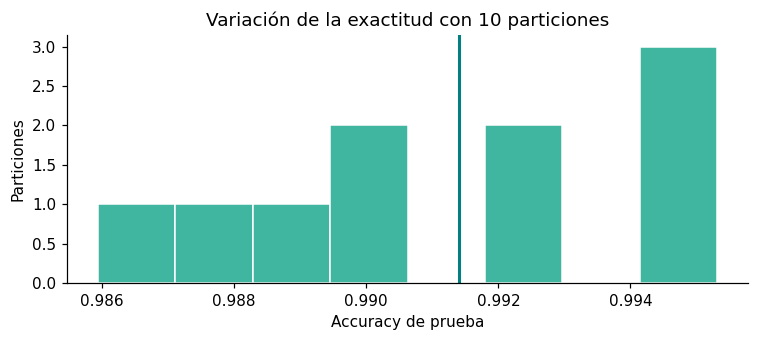

,accuracy,f1
mean,0.9914,0.9918
std,0.0033,0.0032
min,0.9859,0.9865
max,0.9953,0.9955


In [35]:
est = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    pred = np.asarray(clone(pipeline_ganador).fit(Xa, ya).predict(Xb)).ravel()
    est.append({"accuracy": accuracy_score(yb, pred), "f1": f1_score(yb, pred, pos_label=POS)})
est = pd.DataFrame(est)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(est["accuracy"], bins=8, color=COLOR_NOWIN, edgecolor="white")
ax.axvline(est["accuracy"].mean(), color=COLOR_WON, linewidth=2)
ax.set_xlabel("Accuracy de prueba"); ax.set_ylabel("Particiones")
ax.set_title("Variación de la exactitud con 10 particiones")
plt.tight_layout(); plt.show()

est.describe().loc[["mean", "std", "min", "max"]].round(4)

Con 10 particiones distintas, la exactitud media fue 0.9914 (desviación 0.0033), con valores entre 0.9859 y 0.9953. Coincide con la validación cruzada (0.9913) y muestra que el 0.9953 de la partición original está en el extremo alto del rango. El desempeño esperado del modelo es, por tanto, de ≈ 99.1 %.

In [36]:
# Información que el dashboard necesitará: variables, niveles de cada una y métricas
meta = {
    "clase_positiva": POS,
    "variables": list(X.columns),
    "niveles": {c: sorted(X[c].astype(str).unique().tolist()) for c in X.columns},
    "metricas_test": {k: round(float(v), 4) for k, v in metricas_test.items()},
    "ic95_accuracy": [float(ic_acc[0]), float(ic_acc[1])],
}
with open("modelo_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# Comprobación: el pipeline guardado reproduce las predicciones
cargado = joblib.load("modelo_ajedrez.pkl")
assert (np.asarray(cargado.predict(X_test)).ravel() == y_pred).all()

## Conclusiones

Se compararon cuatro algoritmos con el mismo preprocesamiento (One-Hot) sobre 3.196 posiciones y 32 variables categóricas, con una partición estratificada 80/20 y validación cruzada repetida (5 × 3) sobre el 80 % de entrenamiento.
CatBoost obtuvo el F1 medio más alto en validación cruzada (0.9916 ± 0.0030) y el mejor AUC-ROC (0.9995). Supera de forma significativa a la Regresión Logística y, marginalmente, a Random Forest, pero no se distingue del Árbol de Decisión. La línea base de la clase mayoritaria queda en una exactitud de 0.522.
En el conjunto de prueba, el modelo final alcanza Accuracy = 0.9953, F1 = 0.9955 y AUC-ROC ≈ 1, con 3 errores en 640 posiciones (un falso won y dos falsos nowin).
Con 10 particiones distintas la exactitud media es 0.9914 (desviación 0.0033), por lo que el desempeño esperado es de ≈ 99.1 %, algo por debajo del resultado de la partición original.
Las variables que más pesan en el modelo son bknck, rimmx y wxqsq. Cuatro de las cinco principales coinciden con las que el EDA identificó por V de Cramér.
El pipeline completo (One-Hot + CatBoost) se guardó en modelo_ajedrez.pkl para su uso en el dashboard.
Limitaciones. Las diferencias entre CatBoost y los otros modelos de árboles son pequeñas, y no se ajustaron hiperparámetros. Las variables fueron diseñadas por Shapiro como predicados de conocimiento experto sobre el final, no son mediciones libres de partidas reales; esto explica la alta separabilidad de las clases. El resultado describe qué tan bien se aprende esa codificación experta y no debe extrapolarse a partidas reales. Además, este trabajo usa los colores de UCI (peón negro, torre blanca) y lee won como “gana el bando del peón”, porque es lo que indican los datos (todas las posiciones nowin tienen rimmx = f). La tesis original de Shapiro (1983) usa los colores contrarios y UCI rotula las clases como “White-can-win”. Esto afecta la interpretación de las variables, no el desempeño del modelo.